# Notebook 1 - Hiểu dữ liệu và chia tập train / val / test (Bước 1 - 3)

Notebook này làm 3 bước đầu của project dự đoán vỡ nợ trên dữ liệu Lending Club:

1. Tóm tắt yêu cầu đề bài và lập từ điển giải thích toàn bộ các feature
2. Nạp dữ liệu gốc và quan sát ban đầu
3. EDA phục vụ việc chia train / val / test theo thời gian (kiểu Arturo-GA, tỷ lệ 70 / 15 / 15)

**Quy tắc làm việc:** mỗi hàm nằm ở một ô code riêng, mỗi kết quả nằm ở một ô code riêng. Phần markdown chỉ giải thích *làm gì* và *vì sao*. Mọi con số và mọi nhận xét về dữ liệu đều do ô code ngay bên dưới tính và in ra, không gõ tay.

In [1]:
from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Cấu hình hiển thị pandas
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:,.3f}".format)

In [3]:
# Đường dẫn tới file dữ liệu gốc và các thư mục lưu kết quả
ROOT = Path("..") if Path("../data").exists() else Path(".")
DATA_PATH = ROOT / "data/raw/accepted_2007_to_2018Q4.csv"
if not DATA_PATH.exists():
    DATA_PATH = ROOT / "data/raw/accepted_2007_to_2018Q4.csv.gz"

OUT_DIR = ROOT / "data/processed"
ART_DIR = ROOT / "artifacts"
FIG_DIR = ART_DIR / "figures"
for folder in [OUT_DIR, ART_DIR, FIG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

df_raw = pd.read_csv(DATA_PATH, low_memory=False)

In [4]:
df_raw.head()

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,fico_range_low,fico_range_high,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,next_pymnt_d,...,num_rev_tl_bal_gt_0,num_sats,num_tl_120dpd_2m,num_tl_30dpd,num_tl_90g_dpd_24m,num_tl_op_past_12m,pct_tl_nvr_dlq,percent_bc_gt_75,pub_rec_bankruptcies,tax_liens,tot_hi_cred_lim,total_bal_ex_mort,total_bc_limit,total_il_high_credit_limit,revol_bal_joint,sec_app_fico_range_low,sec_app_fico_range_high,sec_app_earliest_cr_line,sec_app_inq_last_6mths,sec_app_mort_acc,sec_app_open_acc,sec_app_revol_util,sec_app_open_act_il,sec_app_num_rev_accts,sec_app_chargeoff_within_12_mths,sec_app_collections_12_mths_ex_med,sec_app_mths_since_last_major_derog,hardship_flag,hardship_type,hardship_reason,hardship_status,deferral_term,hardship_amount,hardship_start_date,hardship_end_date,payment_plan_start_date,hardship_length,hardship_dpd,hardship_loan_status,orig_projected_additional_accrued_interest,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
0,68407277,NaN,"3,600.000","3,600.000","3,600.000",36 months,13.990,123.030,C,C4,leadman,10+ years,MORTGAGE,"55,000.000",Not Verified,Dec-2015,Fully Paid,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,debt_consolidation,Debt consolidation,190xx,PA,5.910,0.000,Aug-2003,675.000,679.000,1.000,30.000,NaN,7.000,0.000,"2,765.000",29.700,13.000,w,0.000,0.000,"4,421.724","4,421.720","3,600.000",821.720,0.000,0.000,0.000,Jan-2019,122.670,NaN,...,4.000,7.000,0.000,0.000,0.000,3.000,76.900,0.000,0.000,0.000,"178,050.000","7,746.000","2,400.000","13,734.000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
1,68355089,NaN,"24,700.000","24,700.000","24,700.000",36 months,11.990,820.280,C,C1,Engineer,10+ years,MORTGAGE,"65,000.000",Not Verified,Dec-2015,Fully Paid,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,small_business,Business,577xx,SD,16.060,1.000,Dec-1999,715.000,719.000,4.000,6.000,NaN,22.000,0.000,"21,470.000",19.200,38.000,w,0.000,0.000,"25,679.660","25,679.660","24,700.000",979.660,0.000,0.000,0.000,Jun-2016,926.350,NaN,...,5.000,22.000,0.000,0.000,0.000,2.000,97.400,7.700,0.000,0.000,"314,017.000","39,475.000","79,300.000","24,667.000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
2,68341763,NaN,"20,000.000","20,000.000","20,000.000",60 months,10.780,432.660,B,B4,truck driver,10+ years,MORTGAGE,"63,000.000",Not Verified,Dec-2015,Fully Paid,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,home_improvement,NaN,605xx,IL,10.780,0.000,Aug-2000,695.000,699.000,0.000,NaN,NaN,6.000,0.000,"7,869.000",56.200,18.000,w,0.000,0.000,"22,705.924","22,705.920","20,000.000","2,705.920",0.000,0.000,0.000,Jun-2017,"15,813.300",NaN,...,3.000,6.000,0.000,0.000,0.000,0.000,100.000,50.000,0.000,0.000,"218,418.000","18,696.000","6,200.000","14,877.000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
3,66310712,NaN,"35,000.000","35,000.000","35,000.000",60 months,14.850,829.900,C,C5,Information Systems Officer,10+ years,MORTGAGE,"110,000.000",Source Verified,Dec-2015,Current,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,debt_consolidation,Debt consolidation

---
# Bước 1 - Tóm tắt yêu cầu đề bài


## 1.1 Bài toán của project

| Mục | Nội dung |
|---|---|
| Loại bài toán | Phân loại nhị phân (credit scoring): dự đoán một khoản vay có vỡ nợ hay không |
| Dữ liệu | Các khoản vay đã được Lending Club chấp nhận, giai đoạn 2007 - 2018 |
| Đầu vào | Thông tin biết được **tại thời điểm xét duyệt**: số tiền vay, kỳ hạn, lãi suất, hạng tín dụng, thu nhập, việc làm, thông tin hồ sơ tín dụng... |
| Đầu ra | Xác suất khoản vay bị vỡ nợ (từ 0 đến 1) |
| Nhãn | `1` nếu `loan_status` là `Charged Off`, `0` nếu là `Fully Paid` |
| Cách chia dữ liệu | Theo thời gian, 70% khoản vay cũ nhất để train, 15% tiếp theo để validation, 15% mới nhất để test |



In [5]:
ALL_COLUMNS = df_raw.columns.tolist()

In [6]:
# Ba nhãn dùng cho giả thuyết "biết được lúc nộp đơn?"
YES, NO, UNCERTAIN = "Yes", "No", "Uncertain"

**Từ điển - nhóm khoản vay**

In [7]:
LOAN_INFO = {
 "id": ("Mã khoản vay do Lending Club gán", NO),
 "member_id": ("Mã thành viên của người vay", NO),
 "url": ("Đường dẫn tới trang của khoản vay trên website Lending Club", NO),
 "loan_amnt": ("Số tiền người vay đề nghị vay (USD)", YES),
 "funded_amnt": ("Số tiền được duyệt/giải ngân cho khoản vay (USD)", UNCERTAIN),
 "funded_amnt_inv": ("Số tiền do nhà đầu tư cấp cho khoản vay (USD)", UNCERTAIN),
 "term": ("Kỳ hạn vay: 36 hoặc 60 tháng", YES),
 "int_rate": ("Lãi suất của khoản vay (%/năm)", YES),
 "installment": ("Số tiền trả góp mỗi tháng (USD)", YES),
 "grade": ("Hạng rủi ro A-G do Lending Club gán", YES),
 "sub_grade": ("Hạng rủi ro chi tiết A1-G5 do Lending Club gán", YES),
 "issue_d": ("Tháng khoản vay được giải ngân (dùng để sắp xếp theo thời gian)", UNCERTAIN),
 "loan_status": ("Trạng thái hiện tại của khoản vay (nguồn tạo nhãn)", NO),
 "pymnt_plan": ("Cờ cho biết khoản vay có kế hoạch trả nợ riêng hay không", UNCERTAIN),
 "purpose": ("Mục đích vay do người vay chọn", YES),
 "title": ("Tiêu đề khoản vay do người vay viết", YES),
 "desc": ("Mô tả khoản vay do người vay viết", YES),
 "initial_list_status": ("Trạng thái niêm yết ban đầu của khoản vay (w hoặc f)", UNCERTAIN),
 "application_type": ("Hồ sơ vay cá nhân (Individual) hay vay chung (Joint App)", YES),
 "policy_code": ("Mã chính sách: sản phẩm công khai hay không công khai", UNCERTAIN),
 "disbursement_method": ("Cách giải ngân: tiền mặt hay trả thẳng cho chủ nợ khác", UNCERTAIN),
}

**Từ điển - nhóm người vay**

In [8]:
BORROWER_INFO = {
 "emp_title": ("Chức danh công việc do người vay nhập", YES),
 "emp_length": ("Số năm làm việc ở công việc hiện tại (dưới 1 năm đến 10+ năm)", YES),
 "home_ownership": ("Tình trạng nhà ở: thuê, thế chấp, sở hữu,...", YES),
 "annual_inc": ("Thu nhập hằng năm do người vay tự khai (USD)", YES),
 "verification_status": ("Thu nhập đã được Lending Club xác minh hay chưa", YES),
 "zip_code": ("3 chữ số đầu của mã bưu chính người vay", YES),
 "addr_state": ("Bang nơi người vay sinh sống", YES),
 "dti": ("Tỷ lệ nợ phải trả hằng tháng trên thu nhập hằng tháng (%), không tính thế chấp nhà và khoản vay này", YES),
}

**Từ điển - nhóm hồ sơ tín dụng (phần 1)**

In [9]:
CREDIT_INFO_1 = {
 "delinq_2yrs": ("Số lần trễ hạn từ 30 ngày trở lên trong 2 năm gần nhất", YES),
 "earliest_cr_line": ("Tháng mở tài khoản tín dụng đầu tiên", YES),
 "fico_range_low": ("Cận dưới của khoảng điểm FICO lúc nộp đơn", YES),
 "fico_range_high": ("Cận trên của khoảng điểm FICO lúc nộp đơn", YES),
 "inq_last_6mths": ("Số lần bị tra cứu tín dụng trong 6 tháng gần nhất", YES),
 "mths_since_last_delinq": ("Số tháng kể từ lần trễ hạn gần nhất", YES),
 "mths_since_last_record": ("Số tháng kể từ hồ sơ công khai tiêu cực gần nhất", YES),
 "open_acc": ("Số tài khoản tín dụng đang mở", YES),
 "pub_rec": ("Số hồ sơ công khai tiêu cực", YES),
 "revol_bal": ("Tổng dư nợ tín dụng quay vòng (USD)", YES),
 "revol_util": ("Phần trăm hạn mức tín dụng quay vòng đã sử dụng", YES),
 "total_acc": ("Tổng số tài khoản tín dụng từng có", YES),
 "collections_12_mths_ex_med": ("Số khoản bị đòi nợ trong 12 tháng, không tính nợ y tế", YES),
 "mths_since_last_major_derog": ("Số tháng kể từ lần vi phạm nghiêm trọng gần nhất (trễ từ 90 ngày)", YES),
 "acc_now_delinq": ("Số tài khoản đang trễ hạn", YES),
 "tot_coll_amt": ("Tổng số tiền từng bị đòi nợ (USD)", YES),
 "tot_cur_bal": ("Tổng dư nợ hiện tại của mọi tài khoản (USD)", YES),
 "open_acc_6m": ("Số tài khoản mở trong 6 tháng gần nhất", YES),
 "open_act_il": ("Số tài khoản trả góp đang hoạt động", YES),
 "open_il_12m": ("Số tài khoản trả góp mở trong 12 tháng gần nhất", YES),
 "open_il_24m": ("Số tài khoản trả góp mở trong 24 tháng gần nhất", YES),
 "mths_since_rcnt_il": ("Số tháng kể từ khi mở tài khoản trả góp gần nhất", YES),
 "total_bal_il": ("Tổng dư nợ các tài khoản trả góp (USD)", YES),
 "il_util": ("Tỷ lệ dư nợ trả góp trên hạn mức cao nhất", YES),
 "open_rv_12m": ("Số tài khoản quay vòng mở trong 12 tháng gần nhất", YES),
 "open_rv_24m": ("Số tài khoản quay vòng mở trong 24 tháng gần nhất", YES),
 "max_bal_bc": ("Dư nợ lớn nhất trên các tài khoản quay vòng (USD)", YES),
 "all_util": ("Tỷ lệ sử dụng trên tổng hạn mức của mọi tài khoản", YES),
 "total_rev_hi_lim": ("Tổng hạn mức cao nhất của các tài khoản quay vòng (USD)", YES),
 "inq_fi": ("Số lần tra cứu tín dụng của công ty tài chính cá nhân", YES),
 "total_cu_tl": ("Số tài khoản tài chính (finance trades)", YES),
 "inq_last_12m": ("Số lần bị tra cứu tín dụng trong 12 tháng gần nhất", YES),
 "acc_open_past_24mths": ("Số tài khoản mở trong 24 tháng gần nhất", YES),
 "avg_cur_bal": ("Dư nợ hiện tại trung bình mỗi tài khoản (USD)", YES),
 "bc_open_to_buy": ("Hạn mức còn lại trên các thẻ ngân hàng quay vòng (USD)", YES),
 "bc_util": ("Tỷ lệ sử dụng hạn mức trên các thẻ ngân hàng", YES),
 "chargeoff_within_12_mths": ("Số lần bị xóa nợ trong 12 tháng gần nhất", YES),
 "delinq_amnt": ("Số tiền đang trễ hạn (USD)", YES),
}

**Từ điển - nhóm hồ sơ tín dụng (phần 2)**

In [10]:
CREDIT_INFO_2 = {
 "mo_sin_old_il_acct": ("Số tháng kể từ khi mở tài khoản trả góp lâu đời nhất", YES),
 "mo_sin_old_rev_tl_op": ("Số tháng kể từ khi mở tài khoản quay vòng lâu đời nhất", YES),
 "mo_sin_rcnt_rev_tl_op": ("Số tháng kể từ khi mở tài khoản quay vòng gần nhất", YES),
 "mo_sin_rcnt_tl": ("Số tháng kể từ khi mở tài khoản bất kỳ gần nhất", YES),
 "mort_acc": ("Số tài khoản thế chấp nhà", YES),
 "mths_since_recent_bc": ("Số tháng kể từ khi mở thẻ ngân hàng gần nhất", YES),
 "mths_since_recent_bc_dlq": ("Số tháng kể từ lần trễ hạn thẻ ngân hàng gần nhất", YES),
 "mths_since_recent_inq": ("Số tháng kể từ lần bị tra cứu tín dụng gần nhất", YES),
 "mths_since_recent_revol_delinq": ("Số tháng kể từ lần trễ hạn tài khoản quay vòng gần nhất", YES),
 "num_accts_ever_120_pd": ("Số tài khoản từng trễ hạn từ 120 ngày", YES),
 "num_actv_bc_tl": ("Số thẻ ngân hàng đang hoạt động", YES),
 "num_actv_rev_tl": ("Số tài khoản quay vòng đang hoạt động", YES),
 "num_bc_sats": ("Số thẻ ngân hàng đang ở trạng thái tốt", YES),
 "num_bc_tl": ("Tổng số thẻ ngân hàng", YES),
 "num_il_tl": ("Số tài khoản trả góp", YES),
 "num_op_rev_tl": ("Số tài khoản quay vòng đang mở", YES),
 "num_rev_accts": ("Số tài khoản quay vòng", YES),
 "num_rev_tl_bal_gt_0": ("Số tài khoản quay vòng có dư nợ lớn hơn 0", YES),
 "num_sats": ("Số tài khoản đang ở trạng thái tốt", YES),
 "num_tl_120dpd_2m": ("Số tài khoản trễ hạn từ 120 ngày (cập nhật trong 2 tháng)", YES),
 "num_tl_30dpd": ("Số tài khoản đang trễ hạn 30 ngày (cập nhật trong 2 tháng)", YES),
 "num_tl_90g_dpd_24m": ("Số tài khoản trễ hạn từ 90 ngày trong 24 tháng gần nhất", YES),
 "num_tl_op_past_12m": ("Số tài khoản mở trong 12 tháng gần nhất", YES),
 "pct_tl_nvr_dlq": ("Phần trăm tài khoản chưa từng trễ hạn", YES),
 "percent_bc_gt_75": ("Phần trăm thẻ ngân hàng đã dùng trên 75% hạn mức", YES),
 "pub_rec_bankruptcies": ("Số lần phá sản trong hồ sơ công khai", YES),
 "tax_liens": ("Số lần bị cầm giữ tài sản vì thuế", YES),
 "tot_hi_cred_lim": ("Tổng hạn mức tín dụng cao nhất (USD)", YES),
 "total_bal_ex_mort": ("Tổng dư nợ, không tính thế chấp nhà (USD)", YES),
 "total_bc_limit": ("Tổng hạn mức các thẻ ngân hàng (USD)", YES),
 "total_il_high_credit_limit": ("Tổng hạn mức cao nhất của các tài khoản trả góp (USD)", YES),
}

**Từ điển - nhóm hồ sơ vay chung**

In [11]:
JOINT_APP_INFO = {
 "annual_inc_joint": ("Thu nhập hằng năm gộp của hai người vay chung (USD)", YES),
 "dti_joint": ("Tỷ lệ nợ trên thu nhập gộp của hai người vay chung (%)", YES),
 "verification_status_joint": ("Thu nhập gộp của hai người vay chung đã được xác minh hay chưa", YES),
 "revol_bal_joint": ("Tổng dư nợ quay vòng gộp của hai người vay chung (USD)", YES),
 "sec_app_fico_range_low": ("Cận dưới điểm FICO của người vay thứ hai", YES),
 "sec_app_fico_range_high": ("Cận trên điểm FICO của người vay thứ hai", YES),
 "sec_app_earliest_cr_line": ("Tháng mở tài khoản tín dụng đầu tiên của người vay thứ hai", YES),
 "sec_app_inq_last_6mths": ("Số lần tra cứu tín dụng 6 tháng của người vay thứ hai", YES),
 "sec_app_mort_acc": ("Số tài khoản thế chấp của người vay thứ hai", YES),
 "sec_app_open_acc": ("Số tài khoản đang mở của người vay thứ hai", YES),
 "sec_app_revol_util": ("Phần trăm hạn mức quay vòng đã dùng của người vay thứ hai", YES),
 "sec_app_open_act_il": ("Số tài khoản trả góp đang hoạt động của người vay thứ hai", YES),
 "sec_app_num_rev_accts": ("Số tài khoản quay vòng của người vay thứ hai", YES),
 "sec_app_chargeoff_within_12_mths": ("Số lần bị xóa nợ 12 tháng của người vay thứ hai", YES),
 "sec_app_collections_12_mths_ex_med": ("Số khoản bị đòi nợ 12 tháng (trừ y tế) của người vay thứ hai", YES),
 "sec_app_mths_since_last_major_derog": ("Số tháng kể từ lần vi phạm nghiêm trọng gần nhất của người vay thứ hai", YES),
}

**Từ điển - nhóm thanh toán sau khi vay**

In [12]:
POST_LOAN_INFO = {
 "out_prncp": ("Số tiền gốc còn nợ (USD)", NO),
 "out_prncp_inv": ("Số tiền gốc còn nợ phần do nhà đầu tư cấp (USD)", NO),
 "total_pymnt": ("Tổng số tiền đã thu được cho đến nay (USD)", NO),
 "total_pymnt_inv": ("Tổng số tiền đã thu được phần của nhà đầu tư (USD)", NO),
 "total_rec_prncp": ("Tổng tiền gốc đã thu được (USD)", NO),
 "total_rec_int": ("Tổng tiền lãi đã thu được (USD)", NO),
 "total_rec_late_fee": ("Tổng phí trả chậm đã thu được (USD)", NO),
 "recoveries": ("Số tiền thu hồi được sau khi khoản vay bị xóa nợ (USD)", NO),
 "collection_recovery_fee": ("Phí thu hồi nợ sau khi bị xóa nợ (USD)", NO),
 "last_pymnt_d": ("Tháng nhận được khoản thanh toán gần nhất", NO),
 "last_pymnt_amnt": ("Số tiền của khoản thanh toán gần nhất (USD)", NO),
 "next_pymnt_d": ("Tháng dự kiến của khoản thanh toán tiếp theo", NO),
 "last_credit_pull_d": ("Tháng Lending Club kéo hồ sơ tín dụng lần gần nhất", NO),
 "last_fico_range_high": ("Cận trên điểm FICO ở lần kéo hồ sơ tín dụng gần nhất", NO),
 "last_fico_range_low": ("Cận dưới điểm FICO ở lần kéo hồ sơ tín dụng gần nhất", NO),
}

**Từ điển - nhóm hỗ trợ khó khăn tài chính**

In [13]:
HARDSHIP_INFO = {
 "hardship_flag": ("Cờ cho biết người vay có kế hoạch hỗ trợ khó khăn tài chính hay không", NO),
 "hardship_type": ("Loại kế hoạch hỗ trợ khó khăn", NO),
 "hardship_reason": ("Lý do xin hỗ trợ khó khăn", NO),
 "hardship_status": ("Trạng thái kế hoạch hỗ trợ khó khăn", NO),
 "deferral_term": ("Số tháng được hoãn trả theo kế hoạch hỗ trợ", NO),
 "hardship_amount": ("Số tiền được hỗ trợ theo kế hoạch (USD)", NO),
 "hardship_start_date": ("Ngày bắt đầu kế hoạch hỗ trợ", NO),
 "hardship_end_date": ("Ngày kết thúc kế hoạch hỗ trợ", NO),
 "payment_plan_start_date": ("Ngày bắt đầu kế hoạch trả nợ mới", NO),
 "hardship_length": ("Số tháng của kế hoạch hỗ trợ", NO),
 "hardship_dpd": ("Số ngày trễ hạn tại thời điểm bắt đầu kế hoạch hỗ trợ", NO),
 "hardship_loan_status": ("Trạng thái khoản vay tại thời điểm bắt đầu kế hoạch hỗ trợ", NO),
 "orig_projected_additional_accrued_interest": ("Lãi dự kiến cộng thêm do kế hoạch hỗ trợ (USD)", NO),
 "hardship_payoff_balance_amount": ("Số dư cần trả hết khi bắt đầu kế hoạch hỗ trợ (USD)", NO),
 "hardship_last_payment_amount": ("Số tiền thanh toán cuối cùng trước khi bắt đầu kế hoạch hỗ trợ (USD)", NO),
}

**Từ điển - nhóm tất toán nợ**

In [14]:
SETTLEMENT_INFO = {
 "debt_settlement_flag": ("Cờ cho biết khoản vay đã chuyển sang công ty tất toán nợ hay chưa", NO),
 "debt_settlement_flag_date": ("Ngày cờ tất toán nợ được cập nhật gần nhất", NO),
 "settlement_status": ("Trạng thái của thỏa thuận tất toán nợ", NO),
 "settlement_date": ("Ngày đạt thỏa thuận tất toán nợ", NO),
 "settlement_amount": ("Số tiền thỏa thuận tất toán (USD)", NO),
 "settlement_percentage": ("Phần trăm số dư mà người vay đồng ý trả khi tất toán", NO),
 "settlement_term": ("Số tháng của thỏa thuận tất toán", NO),
}

In [15]:
GROUPS = [
    ("Loan Information", LOAN_INFO),
    ("Borrower Information", BORROWER_INFO),
    ("Credit History (Part 1)", CREDIT_INFO_1),
    ("Credit History (Part 2)", CREDIT_INFO_2),
    ("Joint Application", JOINT_APP_INFO),
    ("Post-Loan Payments", POST_LOAN_INFO),
    ("Hardship Plan", HARDSHIP_INFO),
    ("Debt Settlement", SETTLEMENT_INFO),
]

Hàm dưới đây ghép tám nhóm thành một bảng từ điển duy nhất, mỗi cột của file gốc một dòng.

In [16]:
def build_dictionary(groups):
    rows = []
    for group_name, cols in groups:
        for col, (meaning, known) in cols.items():
            rows.append({
                "column": col,
                "group": group_name,
                "meaning": meaning,
                "known_at_application": known,
            })
    return pd.DataFrame(rows).set_index("column")

In [17]:
data_dictionary = build_dictionary(GROUPS)
print("Dictionary row count:", len(data_dictionary))

Dictionary row count: 151


Kiểm tra từ điển có **đúng** các cột của file gốc: không thiếu, không thừa, không trùng.

In [18]:
missing_in_dictionary = [c for c in ALL_COLUMNS if c not in data_dictionary.index]
extra_in_dictionary = [c for c in data_dictionary.index if c not in ALL_COLUMNS]

print("Raw columns missing from dictionary:", missing_in_dictionary)
print("Dictionary columns not in raw file:", extra_in_dictionary)
print("Duplicate columns in dictionary:", data_dictionary.index.duplicated().sum())

Raw columns missing from dictionary: []
Dictionary columns not in raw file: []
Duplicate columns in dictionary: 0


In [19]:
assert not missing_in_dictionary and not extra_in_dictionary
assert not data_dictionary.index.duplicated().any()
data_dictionary = data_dictionary.loc[ALL_COLUMNS]   # sắp xếp lại đúng thứ tự cột của file gốc

**Bảng 1.** Số cột trong từng nhóm của từ điển.

In [20]:
group_counts = data_dictionary.groupby("group", sort=False).size().to_frame("num_columns")
group_counts.loc["Total"] = group_counts["num_columns"].sum()
group_counts

,num_columns
group,
Loan Information,21
Borrower Information,8
Credit History (Part 1),38
Post-Loan Payments,15
Joint Application,16
Credit History (Part 2),31
Hardship Plan,15
Debt Settlement,7
Total,151


---
# Bước 2 - Nạp dữ liệu gốc và quan sát ban đầu

## 2.1 Nạp toàn bộ file gốc


In [21]:
df_raw = df_raw.copy()

In [22]:
n_rows, n_cols = df_raw.shape
print(f"Rows: {n_rows:,}, Columns: {n_cols:,}")

Rows: 2,260,701, Columns: 151


In [23]:
memory_gb = df_raw.memory_usage(deep=True).sum() / 1e9
print(f"Memory usage: {memory_gb:.2f} GB")

Memory usage: 3.29 GB


In [24]:
assert list(df_raw.columns) == ALL_COLUMNS
print("Loaded columns match dictionary columns exactly in the same order.")

Loaded columns match dictionary columns exactly in the same order.


## 2.2 Kiểm tra dữ liệu


In [25]:
def summarize_columns(df):
    first_valid = df.apply(lambda s: s.dropna().iloc[0] if s.notna().any() else None)
    summary = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing_count": df.isna().sum(),
        "missing_pct": (df.isna().mean() * 100),
        "nunique": df.nunique(),
        "sample_val": first_valid,
    })
    return summary

In [26]:
col_summary = summarize_columns(df_raw)

print("Distribution of columns by data type:")
print(col_summary["dtype"].value_counts())

Distribution of columns by data type:
dtype
float64    113
str         38
Name: count, dtype: int64


**Bảng 4.** Từ điển ghép với thống kê thật của từng cột.

In [27]:
dictionary_check = data_dictionary[["group", "meaning"]].join(col_summary)
dictionary_check

,group,meaning,dtype,missing_count,missing_pct,nunique,sample_val
column,,,,,,,
id,Loan Information,Mã khoản vay do Lending Club gán,str,0,0.000,2260701,68407277
member_id,Loan Information,Mã thành viên của người vay,float64,2260701,100.000,0,None
loan_amnt,Loan Information,Số tiền người vay đề nghị vay (USD),float64,33,0.001,1572,"3,600.000"
funded_amnt,Loan Information,Số tiền được duyệt/giải ngân cho khoản vay (USD),float64,33,0.001,1572,"3,600.000"
funded_amnt_inv,Loan Information,Số tiền do nhà đầu tư cấp cho khoản vay (USD),float64,33,0.001,10057,"3,600.000"
...,...,...,...,...,...,...,...
settlement_status,Debt Settlement,Trạng thái của thỏa thuận tất toán nợ,str,2226455,98.485,3,COMPLETE
settlement_date,Debt Settlement,Ngày đạt thỏa thuận tất toán nợ,str,2226455,98.485,90,Sep-2017
settlement_amount,Debt Settlement,Số tiền thỏa thuận tất toán (USD),float64,2226455,98.485,21941,"9,915.000"


In [28]:
heavy_missing = col_summary[col_summary["missing_pct"] > 80]
print(f"Number of columns missing > 80% data: {len(heavy_missing)} / {n_cols} columns")
print("Top 20 columns with highest missing rate:")
heavy_missing.sort_values(by="missing_pct", ascending=False)[["missing_pct", "nunique", "dtype"]].head(20)

Number of columns missing > 80% data: 39 / 151 columns
Top 20 columns with highest missing rate:


,missing_pct,nunique,dtype
member_id,100.000,0,float64
orig_projected_additional_accrued_interest,99.617,7487,float64
hardship_end_date,99.517,28,str
hardship_reason,99.517,9,str
hardship_status,99.517,3,str
hardship_type,99.517,1,str
hardship_start_date,99.517,27,str
hardship_loan_status,99.517,5,str
hardship_dpd,99.517,34,float64
hardship_length,99.517,1,float64


## 2.3 Nhãn: xem `loan_status`

**Bảng 6.** Số khoản vay theo từng giá trị của `loan_status` (kể cả giá trị thiếu).

In [29]:
status_table = df_raw["loan_status"].value_counts(dropna=False).to_frame("loan_count")
status_table["pct"] = status_table["loan_count"] / len(df_raw) * 100
status_table

,loan_count,pct
loan_status,,
Fully Paid,1076751,47.629
Current,878317,38.852
Charged Off,268559,11.879
Late (31-120 days),21467,0.950
In Grace Period,8436,0.373
Late (16-30 days),4349,0.192
Does not meet the credit policy. Status:Fully Paid,1988,0.088
Does not meet the credit policy. Status:Charged Off,761,0.034
Default,40,0.002


In [30]:
n_missing_status = df_raw["loan_status"].isna().sum()
print(f"Missing loan_status count: {n_missing_status}")
print("Rows missing loan_status also missing issue_d:", df_raw.loc[df_raw["loan_status"].isna(), "issue_d"].isna().all())
print("These rows have no loan information and will be removed.")

Missing loan_status count: 33
Rows missing loan_status also missing issue_d: True
These rows have no loan information and will be removed.


Trạng thái nào là **kết quả cuối cùng** của khoản vay? Một khoản vay đã kết thúc thì không còn gốc nợ phải trả. Cột `out_prncp` là tiền gốc còn nợ, nên ta tính tỷ lệ khoản vay còn gốc nợ (> 0) theo từng trạng thái. Đây là cách dùng dữ liệu để tự kiểm chứng trạng thái nào đã kết thúc.

**Bảng 7.** Tỷ lệ khoản vay còn nợ gốc theo `loan_status`.

In [31]:
outstanding = df_raw.groupby("loan_status")["out_prncp"].agg(
    loan_count="size", remaining_principal_ratio=lambda s: (s > 0).mean())
outstanding

,loan_count,remaining_principal_ratio
loan_status,,
Charged Off,268559,0.000
Current,878317,0.995
Default,40,1.000
Does not meet the credit policy. Status:Charged Off,761,0.000
Does not meet the credit policy. Status:Fully Paid,1988,0.000
Fully Paid,1076751,0.000
In Grace Period,8436,0.987
Late (16-30 days),4349,0.992
Late (31-120 days),21467,0.999


In [32]:
finished = outstanding[outstanding["remaining_principal_ratio"] == 0].index.tolist()
unfinished = outstanding[outstanding["remaining_principal_ratio"] > 0].index.tolist()
print("Finished loan statuses (zero outstanding principal):", finished)
print("Unfinished loan statuses (remaining principal > 0):", unfinished)

Finished loan statuses (zero outstanding principal): ['Charged Off', 'Does not meet the credit policy. Status:Charged Off', 'Does not meet the credit policy. Status:Fully Paid', 'Fully Paid']
Unfinished loan statuses (remaining principal > 0): ['Current', 'Default', 'In Grace Period', 'Late (16-30 days)', 'Late (31-120 days)']


Trong các trạng thái đã kết thúc có hai trạng thái ghi rõ là *Does not meet the credit policy*, tức là thuộc chính sách cho vay cũ. Để giữ bài toán đơn giản và đồng nhất sản phẩm vay, ta chỉ lấy hai trạng thái chuẩn `Fully Paid` (nhãn 0) và `Charged Off` (nhãn 1). Ô sau cho biết việc loại hai trạng thái chính sách cũ làm mất bao nhiêu dòng.

In [33]:
old_policy = [s for s in finished if "credit policy" in s]
n_old_policy = df_raw["loan_status"].isin(old_policy).sum()
print(f"Old credit policy loans (excluded): {n_old_policy:,}")
print(f"Accounting for {n_old_policy / len(df_raw) * 100:.2f}% of total rows.")

Old credit policy loans (excluded): 2,749
Accounting for 0.12% of total rows.


In [34]:
LABEL_MAP = {"Fully Paid": 0, "Charged Off": 1}
df_raw["default"] = df_raw["loan_status"].map(LABEL_MAP)
print("Labelled row count:", df_raw["default"].notna().sum())

Labelled row count: 1345310


In [35]:
label_counts = df_raw["default"].value_counts().rename({0: "0 = Fully Paid", 1: "1 = Charged Off"}).to_frame("loan_count")
label_counts["pct"] = label_counts["loan_count"] / label_counts["loan_count"].sum() * 100
label_counts

,loan_count,pct
default,,
0 = Fully Paid,1076751,80.037
1 = Charged Off,268559,19.963


## 2.4 Đổi ngày giải ngân và kỳ hạn sang dạng số
Cột `issue_d` có dạng chữ như `Dec-2015`, cột `term` có dạng `" 36 months"`. Hai hàm nhỏ sau đổi chúng sang dạng dùng được.

In [36]:
def parse_month(series):
    return pd.to_datetime(series, format="%b-%Y")

In [37]:
def parse_term_months(series):
    return series.str.extract(r"(\d+)")[0].astype(float)

In [38]:
df_raw["issue_date"] = parse_month(df_raw["issue_d"])
df_raw["term_months"] = parse_term_months(df_raw["term"])
df_raw["year"] = df_raw["issue_date"].dt.year

In [39]:
print("Earliest issue date:", df_raw["issue_date"].min().date())
print("Latest issue date:", df_raw["issue_date"].max().date())
print("Loan terms in data (months):", sorted(int(t) for t in df_raw["term_months"].dropna().unique()))

Earliest issue date: 2007-06-01
Latest issue date: 2018-12-01
Loan terms in data (months): [36, 60]


---
# Bước 3 - EDA phục vụ việc chia train / val / test

**Tham khảo cách làm của người khác** (nêu tên và kỹ thuật; chưa đối chiếu nội dung gốc, mọi điều rút ra cho dữ liệu của ta đều do code bên dưới kiểm chứng):
- Arturo-GA, `lendingclub-default-risk` - https://github.com/Arturo-GA/lendingclub-default-risk : chia theo thời gian 70/15/15, chỉ dùng khoản vay đã đáo hạn.
- vaibhavkev, `credit-risk` - https://github.com/vaibhavkev/credit-risk : chia train/validation/test theo thời gian.
- Xia và cộng sự, SurvXGBoost - https://journals.vilniustech.lt/index.php/TEDE/article/view/13997 : đánh giá cả out-of-sample lẫn out-of-time.

## 3.1 Số khoản vay, tỷ lệ vỡ nợ và tỷ lệ đã có kết quả theo năm

In [40]:
df_raw["resolved"] = df_raw["default"].notna()

In [41]:
by_year = df_raw.groupby("year").agg(
    loan_count=("resolved", "size"),
    resolved_rate=("resolved", "mean"),
    default_rate_in_resolved=("default", "mean"),
    term_60_share=("term_months", lambda s: (s == 60).mean()),
) # mean --> tỉlệ vỡ nợ vì biến binary
by_year.index = by_year.index.astype(int).astype(str)
by_year

,loan_count,resolved_rate,default_rate_in_resolved,term_60_share
year,,,,
2007,603,0.416,0.179,0.000
2008,2393,0.653,0.158,0.000
2009,5281,0.893,0.126,0.000
2010,12537,0.920,0.129,0.270
2011,21721,1.000,0.152,0.351
2012,53367,1.000,0.162,0.185
2013,134814,1.000,0.156,0.255
2014,235629,0.947,0.184,0.310
2015,421095,0.892,0.202,0.328


In [42]:
low_year = by_year["resolved_rate"].idxmin()
print(f"Year with lowest resolved rate: {low_year} ({by_year.loc[low_year, 'resolved_rate']:.1%}).")
print(f"Year with highest default rate: {by_year['default_rate_in_resolved'].idxmax()} "
      f"({by_year['default_rate_in_resolved'].max():.3f}); lowest: "
      f"{by_year['default_rate_in_resolved'].idxmin()} ({by_year['default_rate_in_resolved'].min():.3f}).")
print("Action -> Loans near dataset end have not had time to resolve, causing target skew; need a maturity filter (Section 3.3).")

Year with lowest resolved rate: 2018 (11.4%).
Year with highest default rate: 2016 (0.233); lowest: 2009 (0.126).
Action -> Loans near dataset end have not had time to resolve, causing target skew; need a maturity filter (Section 3.3).


## 3.2 Bắt đầu từ năm nào?
Các năm đầu có rất ít khoản vay. Ta xem mỗi năm chiếm bao nhiêu phần trăm số khoản vay có nhãn, và các cột hồ sơ tín dụng bắt đầu có dữ liệu từ năm nào.

In [43]:
labelled_per_year = df_raw[df_raw["resolved"]].groupby("year").size()
share_per_year = (labelled_per_year / labelled_per_year.sum() * 100).to_frame("share_pct_in_labelled")
share_per_year.index = share_per_year.index.astype(int).astype(str)
share_per_year["num_labelled_loans"] = labelled_per_year.values
share_per_year

,share_pct_in_labelled,num_labelled_loans
year,,
2007,0.019,251
2008,0.116,1562
2009,0.351,4716
2010,0.857,11536
2011,1.615,21721
2012,3.967,53367
2013,10.020,134804
2014,16.584,223102
2015,27.915,375545


Hàm sau trả về năm đầu tiên một cột có dữ liệu (không thiếu).

In [44]:
def first_year_with_data(df, column):
    return df.loc[df[column].notna(), "year"].min()

In [45]:
float_columns = [c for c in ALL_COLUMNS if df_raw[c].dtype == "float64"]
first_years = pd.Series({c: first_year_with_data(df_raw, c) for c in float_columns})

In [46]:
empty_columns = first_years[first_years.isna()].index.tolist()
print(f"Numeric columns with no values in any year: {len(empty_columns)} -> {empty_columns}")
first_years = first_years.dropna()

Numeric columns with no values in any year: 1 -> ['member_id']


In [47]:
first_year_counts = first_years.astype(int).value_counts().sort_index().to_frame("num_numeric_columns_starting_this_year")
first_year_counts.index = first_year_counts.index.astype(str)
first_year_counts

,num_numeric_columns_starting_this_year
2007,40
2012,44
2015,16
2017,12


In [48]:
START_YEAR = 2010   
before = labelled_per_year[labelled_per_year.index < START_YEAR].sum()
print(f"Years before {START_YEAR} only have {before:,} labelled loans, accounting for {before / labelled_per_year.sum():.2%} of total.")
late_columns = (first_years > START_YEAR).sum()
print(f"There are {late_columns} numeric columns that only have data after {START_YEAR}.")
print(f"Decision -> start from year {START_YEAR}: discards very little data. Late columns will be addressed in Step 5.")

Years before 2010 only have 6,529 labelled loans, accounting for 0.49% of total.
There are 72 numeric columns that only have data after 2010.
Decision -> start from year 2010: discards very little data. Late columns will be addressed in Step 5.


## 3.3 Luật "đã đáo hạn"
Khoản vay phát hành năm 2018 với kỳ hạn 36 tháng chưa thể kết thúc. Nếu giữ lại, nhãn của chúng thiên về những khoản kết thúc sớm. Ta định nghĩa: một khoản vay **đã đáo hạn** nếu tháng giải ngân cộng kỳ hạn không muộn hơn tháng cuối cùng của dữ liệu.



In [49]:
SNAPSHOT = df_raw["issue_date"].max()
print("Latest month in data (SNAPSHOT):", SNAPSHOT.strftime("%Y-%m"))

Latest month in data (SNAPSHOT): 2018-12


In [50]:

def month_number(dates):
    return dates.dt.year * 12 + dates.dt.month

In [51]:
def is_matured(issue_date, term_months, snapshot):
    end_month = month_number(issue_date) + term_months
    return end_month <= snapshot.year * 12 + snapshot.month

In [52]:
df_raw["matured"] = is_matured(df_raw["issue_date"], df_raw["term_months"], SNAPSHOT)
print("Number of matured loans:", df_raw["matured"].sum())

Number of matured loans: 676459


**Kiểm chứng luật.** Nếu luật đúng thì trong nhóm đã đáo hạn, hầu hết khoản vay phải đã có kết quả cuối cùng; còn trong nhóm chưa đáo hạn, tỷ lệ đó phải thấp hơn nhiều.

**Bảng 8.** Tỷ lệ đã có kết quả cuối cùng, theo nhóm đáo hạn.

In [53]:
maturity_check = df_raw.groupby("matured").agg(
    loan_count=("resolved", "size"),
    resolved_rate=("resolved", "mean"),
    default_rate_in_resolved=("default", "mean"),
    share_60=("term_months", lambda s: (s == 60).mean()),
)
maturity_check.index = maturity_check.index.map({True: "matured", False: "unmatured"})
maturity_check

,loan_count,resolved_rate,default_rate_in_resolved,share_60
matured,,,,
unmatured,1584242,0.424,0.251,0.376
matured,676459,0.996,0.148,0.082


In [54]:
rate_matured = maturity_check.loc["matured", "resolved_rate"]
rate_not = maturity_check.loc["unmatured", "resolved_rate"]
print(f"Matured group: {rate_matured:.1%} have final outcomes. Unmatured group: {rate_not:.1%}.")
print("Rule successfully separates the two groups." if rate_matured > rate_not else "Rule does NOT separate the two groups - review needed.")
print(f"Action -> keep matured group. {1 - rate_matured:.1%} matured loans still without final outcomes (late, deferred...) will be removed in labelling filter.")

Matured group: 99.6% have final outcomes. Unmatured group: 42.4%.
Rule successfully separates the two groups.
Action -> keep matured group. 0.4% matured loans still without final outcomes (late, deferred...) will be removed in labelling filter.


## 3.4 Các bộ lọc và số dòng còn lại
Ba bộ lọc: có nhãn, từ năm bắt đầu, đã đáo hạn. Bảng cho thấy mỗi bộ lọc loại bao nhiêu dòng.

**Bảng 9.** Số dòng sau từng bộ lọc.

In [55]:
is_labelled = df_raw["default"].notna()
from_start_year = df_raw["year"] >= START_YEAR
is_old_enough = df_raw["matured"]

In [56]:
steps = [
    ("Total raw data", pd.Series(True, index=df_raw.index)),
    ("Labelled (Fully Paid / Charged Off)", is_labelled),
    (f"... and issued from {START_YEAR}", is_labelled & from_start_year),
    ("... and matured", is_labelled & from_start_year & is_old_enough),
]
filter_table = pd.DataFrame({"num_rows": [mask.sum() for _, mask in steps]}, index=[name for name, _ in steps])
filter_table["retention_pct"] = filter_table["num_rows"] / len(df_raw) * 100
filter_table["step_reduction_pct"] = (1 - filter_table["num_rows"] / filter_table["num_rows"].shift(1).fillna(filter_table["num_rows"].iloc[0])) * 100
filter_table

,num_rows,retention_pct,step_reduction_pct
Total raw data,2260701,100.000,0.000
Labelled (Fully Paid / Charged Off),1345310,59.509,40.491
... and issued from 2010,1338781,59.220,0.485
... and matured,667024,29.505,50.177


In [57]:
final_mask = is_labelled & from_start_year & is_old_enough
loans = df_raw[final_mask].copy()
print(f"Project dataset: {len(loans):,} rows ({len(loans) / len(df_raw):.1%} of raw file).")
print(f"Default rate in this dataset: {loans['default'].mean():.3f}")
print(f"Issue date from {loans['issue_date'].min():%Y-%m} to {loans['issue_date'].max():%Y-%m}.")

Project dataset: 667,024 rows (29.5% of raw file).
Default rate in this dataset: 0.148
Issue date from 2010-01 to 2015-12.


## 3.5 Chia 70 / 15 / 15 theo thời gian
Hàm `time_split` sắp các khoản vay theo ngày giải ngân, tìm hai **ngày cắt** tại vị trí 70% và 85% rồi chia theo ngày. Chia theo ngày (không phải theo vị trí dòng) để không có tháng nào nằm ở hai tập cùng lúc.

In [58]:
def time_split(df, train_share=0.70, val_share=0.15):
    df = df.sort_values(["issue_date", "id"]).reset_index(drop=True)
    cut_val = df["issue_date"].iloc[int(len(df) * train_share)]
    cut_test = df["issue_date"].iloc[int(len(df) * (train_share + val_share))]
    train = df[df["issue_date"] < cut_val]
    val = df[(df["issue_date"] >= cut_val) & (df["issue_date"] < cut_test)]
    test = df[df["issue_date"] >= cut_test]
    return train, val, test, cut_val, cut_test

In [59]:
train, val, test, CUT_VAL, CUT_TEST = time_split(loans, 0.70, 0.15)
print("Validation set start date:", CUT_VAL.date())
print("Test set start date:", CUT_TEST.date())

Validation set start date: 2015-05-01
Test set start date: 2015-09-01


In [60]:
assert train["issue_date"].max() < val["issue_date"].min()
assert val["issue_date"].max() < test["issue_date"].min()
assert len(train) + len(val) + len(test) == len(loans)
print("Check passed: train < val < test chronologically, no rows lost or duplicated.")

Check passed: train < val < test chronologically, no rows lost or duplicated.


**Bảng 10.** Ba tập sau khi chia.

In [61]:
split_table = pd.DataFrame({
    "num_rows": [len(train), len(val), len(test)],
    "pct_of_total": [len(x) / len(loans) * 100 for x in (train, val, test)],
    "from_month": [x["issue_date"].min().strftime("%Y-%m") for x in (train, val, test)],
    "to_month": [x["issue_date"].max().strftime("%Y-%m") for x in (train, val, test)],
    "default_rate": [x["default"].mean() for x in (train, val, test)],
}, index=["train", "val", "test"])
split_table

,num_rows,pct_of_total,from_month,to_month,default_rate
train,464185,69.590,2010-01,2015-04,0.148
val,95405,14.303,2015-05,2015-08,0.148
test,107434,16.106,2015-09,2015-12,0.148


**Bảng 11.** Cơ cấu kỳ hạn (36 / 60 tháng) trong từng tập. Luật đáo hạn có thể làm lệch cơ cấu này, vì khoản vay 60 tháng cần nhiều thời gian hơn mới đáo hạn.

In [62]:
term_mix = pd.DataFrame({name: x["term_months"].value_counts(normalize=True)
                         for name, x in [("train", train), ("val", val), ("test", test)]}).fillna(0)
term_mix.index = term_mix.index.astype(int).astype(str) + " months"
term_mix

,train,val,test
term_months,,,
36 months,0.882,1.000,1.000
60 months,0.118,0.000,0.000


In [63]:
last_issue_by_term = loans.groupby("term_months")["issue_date"].max()
share_60 = {name: (x["term_months"] == 60).mean() for name, x in [("train", train), ("val", val), ("test", test)]}
print(f"60-month loan proportion: train {share_60['train']:.1%}, val {share_60['val']:.1%}, test {share_60['test']:.1%}.")
print(f"Latest issue month remaining: 36-month {last_issue_by_term[36.0]:%Y-%m}, 60-month {last_issue_by_term[60.0]:%Y-%m}.")
if share_60["test"] < share_60["train"] - 0.05:
    print("Maturity rule creates term shift: 60-month loans issued late have not matured, so they are absent in the test set.")
    print("Action -> document as a limitation; when evaluating models, note that test set consists almost entirely of 36-month loans.")
else:
    print("Term structure across splits is not significantly skewed.")

60-month loan proportion: train 11.8%, val 0.0%, test 0.0%.
Latest issue month remaining: 36-month 2015-12, 60-month 2013-12.
Maturity rule creates term shift: 60-month loans issued late have not matured, so they are absent in the test set.
Action -> document as a limitation; when evaluating models, note that test set consists almost entirely of 36-month loans.


**Biểu đồ 1.** Số khoản vay (cột) và tỷ lệ vỡ nợ (đường) theo tháng giải ngân, kèm hai đường cắt giữa train / val / test.

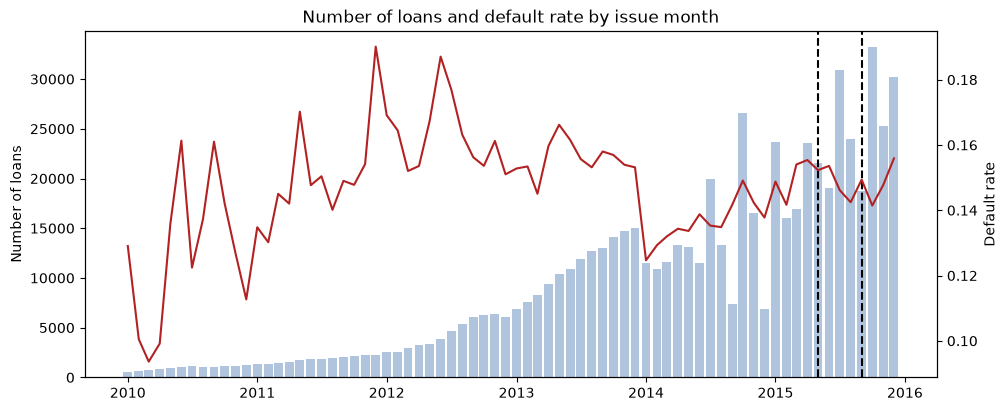

In [64]:
monthly = loans.groupby("issue_date").agg(loan_count=("default", "size"), default_rate=("default", "mean"))

fig, ax1 = plt.subplots(figsize=(11, 4.5))
ax1.bar(monthly.index, monthly["loan_count"], width=25, color="lightsteelblue")
ax1.set_ylabel("Number of loans")
ax2 = ax1.twinx()
ax2.plot(monthly.index, monthly["default_rate"], color="firebrick")
ax2.set_ylabel("Default rate")
for cut in (CUT_VAL, CUT_TEST):
    ax1.axvline(cut, color="black", linestyle="--")
ax1.set_title("Number of loans and default rate by issue month")
plt.savefig(FIG_DIR / "01_chia_theo_thoi_gian.png", dpi=150, bbox_inches="tight")
plt.show()

In [65]:
rates = split_table["default_rate"]
print(f"Default rates: train {rates['train']:.3f}, val {rates['val']:.3f}, test {rates['test']:.3f}.")
print(f"Month with most loans: {monthly['loan_count'].idxmax():%Y-%m} ({monthly['loan_count'].max():,} loans).")
spread = rates.max() - rates.min()
if spread < 0.005:
    print(f"Default rates across all three splits are nearly identical (maximum difference {spread:.4f}).")
    print("This means after filtering for matured loans, the target is no longer temporally skewed as observed in step 3.1.")
else:
    print(f"Default rate difference across splits is {spread:.3f}: the model will face temporal drift.")

Default rates: train 0.148, val 0.148, test 0.148.
Month with most loans: 2015-10 (33,186 loans).
Default rates across all three splits are nearly identical (maximum difference 0.0003).
This means after filtering for matured loans, the target is no longer temporally skewed as observed in step 3.1.


## 3.6 Lưu ba tập và bản ghi cách chia
Ba tập được lưu giữ nguyên đủ 151 cột gốc (cộng thêm vài cột phụ vừa tạo) để Notebook 2 dùng. Bản ghi `split_manifest.json` có số dòng, ngày cắt và dấu vân tay MD5 của các `id` trong tập train, để sau này kiểm tra được ai đó khác có cùng tập train hay không.

In [66]:
train.to_parquet(OUT_DIR / "train.parquet", index=False)
val.to_parquet(OUT_DIR / "val.parquet", index=False)
test.to_parquet(OUT_DIR / "test.parquet", index=False)
data_dictionary.to_csv(OUT_DIR / "data_dictionary.csv", encoding="utf-8-sig")
print("Saved train, val, test and data_dictionary.csv to", OUT_DIR.resolve())

Saved train, val, test and data_dictionary.csv to /home/orlab/Documents/Study materials/Lending-Club-Credit-Scoring/data/processed


In [67]:
manifest = {
    "rule": "matured loans with labels, issued from START_YEAR; sorted by issue_d; time split 70/15/15 by date",
    "start_year": START_YEAR,
    "snapshot": SNAPSHOT.strftime("%Y-%m"),
    "cut_val": str(CUT_VAL.date()),
    "cut_test": str(CUT_TEST.date()),
    "num_rows": {"train": len(train), "val": len(val), "test": len(test)},
    "default_rate": {"train": round(float(rates["train"]), 4), "val": round(float(rates["val"]), 4), "test": round(float(rates["test"]), 4)},
    "md5_id_train": hashlib.md5(",".join(sorted(train["id"])).encode()).hexdigest(),
}
(ART_DIR / "split_manifest.json").write_text(json.dumps(manifest, indent=2, ensure_ascii=False))
print(json.dumps(manifest, indent=2, ensure_ascii=False))

{
  "rule": "matured loans with labels, issued from START_YEAR; sorted by issue_d; time split 70/15/15 by date",
  "start_year": 2010,
  "snapshot": "2018-12",
  "cut_val": "2015-05-01",
  "cut_test": "2015-09-01",
  "num_rows": {
    "train": 464185,
    "val": 95405,
    "test": 107434
  },
  "default_rate": {
    "train": 0.1483,
    "val": 0.1481,
    "test": 0.1484
  },
  "md5_id_train": "6f7434f3acf1530aed7611dbd34eb1c5"
}


In [68]:
train.head()

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,fico_range_low,fico_range_high,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,next_pymnt_d,...,pct_tl_nvr_dlq,percent_bc_gt_75,pub_rec_bankruptcies,tax_liens,tot_hi_cred_lim,total_bal_ex_mort,total_bc_limit,total_il_high_credit_limit,revol_bal_joint,sec_app_fico_range_low,sec_app_fico_range_high,sec_app_earliest_cr_line,sec_app_inq_last_6mths,sec_app_mort_acc,sec_app_open_acc,sec_app_revol_util,sec_app_open_act_il,sec_app_num_rev_accts,sec_app_chargeoff_within_12_mths,sec_app_collections_12_mths_ex_med,sec_app_mths_since_last_major_derog,hardship_flag,hardship_type,hardship_reason,hardship_status,deferral_term,hardship_amount,hardship_start_date,hardship_end_date,payment_plan_start_date,hardship_length,hardship_dpd,hardship_loan_status,orig_projected_additional_accrued_interest,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term,default,issue_date,term_months,year,resolved,matured
0,367030,NaN,"11,200.000","11,200.000","11,000.000",36 months,7.880,350.340,A,A5,TDM Services,3 years,OTHER,"25,000.000",Not Verified,Jan-2010,Charged Off,n,https://lendingclub.com/browse/loanDetail.acti...,I would like a loan with a favorable interest ...,debt_consolidation,BPK Loan,300xx,GA,19.150,0.000,Jul-1993,735.000,739.000,0.000,NaN,NaN,9.000,0.000,"10,485.000",36.200,18.000,f,0.000,0.000,"10,860.540","10,666.990","9,477.280","1,377.370",0.000,5.890,0.000,Sep-2012,350.340,NaN,...,NaN,NaN,0.000,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,1.000,2010-01-01,36.000,"2,010.000",True,True
1,377437,NaN,"14,000.000","14,000.000","14,000.000",36 months,15.310,487.420,D,D3,Barix Clinix of Ohio,7 years,MORTGAGE,"65,000.000",Not Verified,Jan-2010,Fully Paid,n,https://lendingclub.com/browse/loanDetail.acti...,This is a loan to pay off three credit cards I...,debt_consolidation,Paying off Credit Cards,431xx,OH,23.130,0.000,Oct-1999,680.000,684.000,0.000,NaN,92.000,12.000,1.000,"13,641.000",97.400,16.000,f,0.000,0.000,"17,369.132","17,369.130","14,000.000","3,369.140",0.000,0.000,0.000,Aug-2012,14.830,NaN,...,NaN,NaN,1.000,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,0.000,2010-01-01,36.000,"2,010.000",True,True
2,395561,NaN,"24,000.000","24,000.000","22,598.498",36 months,20.860,902.540,G,G4,United States Army,10+ years,MORTGAGE,"119,450.000",Verified,Jan-2010,Fully Paid,n,https://lendingclub.com/browse/loanDetail.acti...,"I currently have (29 Apr 2009) $154,000 in all...",credit_card,Credit Card 16%,238xx,VA,20.920,1.000,Sep-1992,665.000,669.000,0.000,17.000,NaN,14.000,0.000,"45,414.000",98.300,33.000,f,0.000,0.000,"32,493.205","30,511.440","24,000.000","8,493.210",0.000,0.000,0.000,Jan-2013,909.880,NaN,...,NaN,NaN,0.000,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,0.000,2010-01-01,36.000,"2,010.000",True,True
3,399980,NaN,"9,600.000","9,600.000","9,375.000",36 months,12.180,319.680,B,B4,Abc Supply,3 years,RENT,"45,000.000",Not Verified,Jan-2010,Fully Paid,n,https://lendingclub.com/browse/loanDetail.acti...,I am trying to get out of a high ca